In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
from matplotlib.widgets import RadioButtons, Slider
%matplotlib widget

df = pd.read_excel("US-Superstore-data.xls")

# Display all column names
print(df.columns)

# Initial Exploration
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove Duplicate Rows
df = df.drop_duplicates()

# Standardize Column Names
# Remove extra spaces and replace spaces with underscores

df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Handle Missing Values
# Numerical columns: fill with median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns: fill with mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert Date Columns
date_cols = ["Order_Date", "Ship_Date"]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

# Remove Leading/Trailing Spaces
# From Text Columns

for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

# Check Data Types
print("\nData Types:")
print(df.dtypes)

# Check for Remaining Missing Values

print("\nRemaining Missing Values:")
print(df.isnull().sum())

# Summary Statistics
print("\nSummary Statistics:")
print(df.describe())

# Save Cleaned Dataset
df.to_csv("US-Superstore-data-cleaned.csv", index=False)

print("\nCleaning complete.")

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')
Dataset Shape: (9994, 21)

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate Rows: 0


C:\Users\USER1\AppData\Local\Temp\ipykernel_29116\319843637.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns



Data Types:
Row_ID                    int64
Order_ID                    str
Order_Date       datetime64[us]
Ship_Date        datetime64[us]
Ship_Mode                   str
Customer_ID                 str
Customer_Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal_Code               int64
Region                      str
Product_ID                  str
Category                    str
Sub-Category                str
Product_Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

Remaining Missing Values:
Row_ID           0
Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Customer_ID      0
Customer_Name    0
Segment          0
Country          0
City             0
State            0
Postal_Code      0
Region           0
Product_ID       0
Category

In [5]:
print(df.columns.tolist())

['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub-Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit']


Selected Region: All


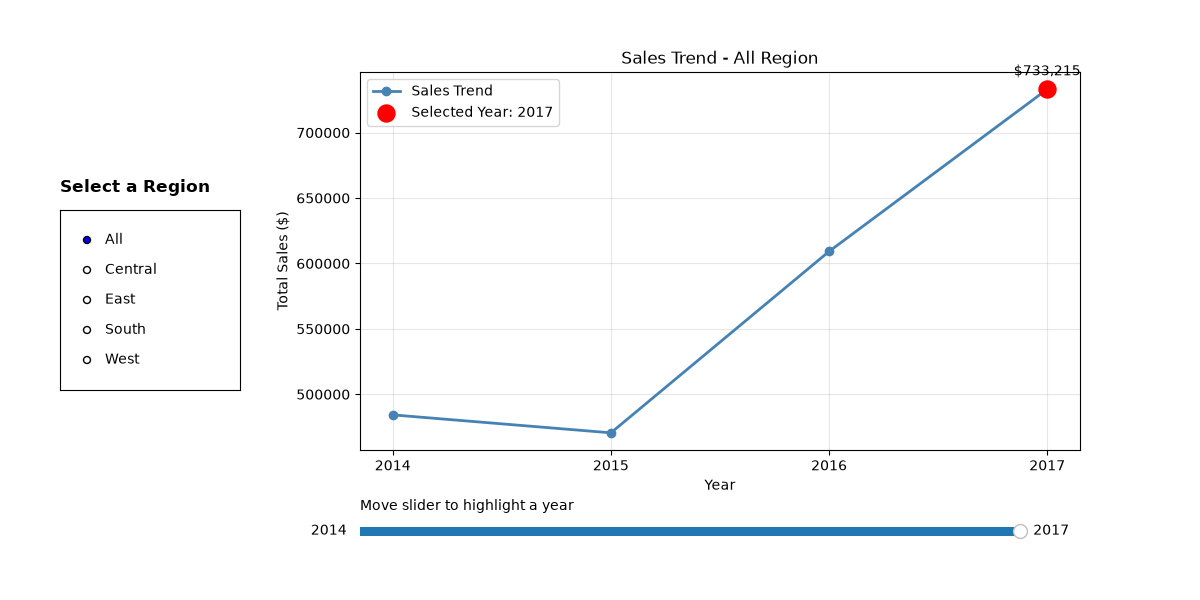

In [13]:
# DATA PREPARATION
# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Convert Order_Date column to datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Create Year column from Order_Date
df['Year'] = df['Order_Date'].dt.year

# Create list of regions for radio buttons
regions = ['All'] + sorted(df['Region'].unique())

# Get unique years from dataset
years = sorted(df['Year'].unique())

# CREATE FIGURE

fig, ax = plt.subplots(figsize=(12, 6))

# Make room for widgets
plt.subplots_adjust(left=0.30, bottom=0.25)

# RADIO BUTTONS

rax = plt.axes([0.05, 0.35, 0.15, 0.30])

radio = RadioButtons(
    rax,
    regions
)

# Add instruction text to figure
fig.text(
    0.05,
    0.68,
    "Select a Region",
    fontsize=12,
    fontweight='bold'
)

# YEAR SLIDER

sax = plt.axes([0.30, 0.10, 0.55, 0.03])

year_slider = Slider(
    ax=sax,
    label='2014',
    valmin=0,
    valmax=len(years) - 1,
    valinit=len(years) - 1,
    valstep=1
)
fig.text(
    0.30,
    0.15,
    "Move slider to highlight a year",
    fontsize=10
)

# UPDATE CHART

def update(val):

    # Get currently selected region
    region = radio.value_selected
    print(f"Selected Region: {region}")

    # Convert slider position to actual year
    selected_year = years[int(year_slider.val)]

    # Display actual year in slider text
    year_slider.valtext.set_text(str(selected_year))

    # Filter data by region
    if region == 'All':
        filtered_df = df.copy()
    else:
        filtered_df = df[df['Region'] == region]

    # Calculate total sales for each year
    sales_by_year = (
        filtered_df
        .groupby('Year')['Sales']
        .sum()
        .reset_index()
        .sort_values('Year')
    )

    # Get the row corresponding to the selected year
    selected_data = sales_by_year[
        sales_by_year['Year'] == selected_year
    ]

    # Clear chart before redrawing
    ax.clear()

    # Draw trend line for all years
    ax.plot(
        sales_by_year['Year'],
        sales_by_year['Sales'],
        marker='o',
        linewidth=2,
        color='steelblue',
        label='Sales Trend'
    )

    # Highlight currently selected year
    if not selected_data.empty:
        ax.scatter(
            selected_data['Year'],
            selected_data['Sales'],
            color='red',
            s=150,
            zorder=5,
            label=f'Selected Year: {selected_year}'
        )

        # Add annotation showing sales value
        sales_value = selected_data['Sales'].iloc[0]

        ax.annotate(
            f'${sales_value:,.0f}',
            (
                selected_data['Year'].iloc[0],
                selected_data['Sales'].iloc[0]
            ),
            xytext=(0, 10),
            textcoords='offset points',
            ha='center'
        )

    # Show all years on x-axis
    ax.set_xticks(years)

    # Chart labels
    ax.set_title(f'Sales Trend - {region} Region')
    ax.set_xlabel('Year')
    ax.set_ylabel('Total Sales ($)')

    ax.grid(True, alpha=0.3)
    ax.legend()

    # Refresh chart
    fig.canvas.draw_idle()

    # Refresh chart
    fig.canvas.draw_idle()

# INITIAL CHART
update(None)

# CONNECT WIDGETS
radio.on_clicked(update)
year_slider.on_changed(update)

plt.show()

In [10]:
print(df['Region'].unique())

# Clean Region values
df['Region'] = df['Region'].str.strip()

regions = ['All'] + sorted(df['Region'].unique())

<StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str


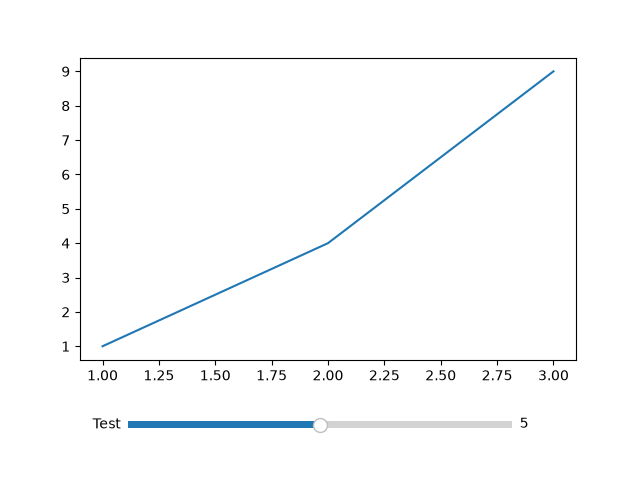

In [2]:
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
%matplotlib widget
fig, ax = plt.subplots()
plt.subplots_adjust(bottom=0.25)

ax.plot([1, 2, 3], [1, 4, 9])

slider_ax = plt.axes([0.2, 0.1, 0.6, 0.03])

slider = Slider(
    slider_ax,
    "Test",
    0,
    10,
    valinit=5
)

def update(val):
    print("Slider moved:", slider.val)

slider.on_changed(update)

plt.show()

In [10]:
import matplotlib

print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline
